# ClaimsSQL-Trust â€” figures for the report

This notebook only **reads the CSV tables in `results/tables/`** and draws the
figures. All numbers are computed by `python -m claimssql.eval.report --run-id full`;
run that first if the tables are missing or out of date.

Each figure is saved to `results/figures/` as a 300-dpi PNG. The figures use grey
levels, hatching, markers and line styles instead of colour, so they stay readable
in a black-and-white print. Models always appear in the order qwen, gemma, mid_oss.
Unless a note says otherwise, a figure shows the **test split** (160 questions:
96 answerable, 64 infeasible). The drawing code is in `src/claimssql/eval/figures.py`.

In [1]:
import pandas as pd
from IPython.display import display

from claimssql.config import REPO_ROOT
from claimssql.eval import figures

TABLES = REPO_ROOT / "results" / "tables"
FIGURES = REPO_ROOT / "results" / "figures"


def draw(name: str):
    """Draw one figure, save it as PNG and show it."""
    fig = figures.FIGURES[name](TABLES)
    path = figures.save(fig, FIGURES / f"{name}.png")
    print("saved", path.relative_to(REPO_ROOT).as_posix())
    return fig


info = pd.read_csv(TABLES / "bootstrap_info.csv")
display(info)
print("Models, in figure order:", figures.model_order(TABLES))

,split,questions,resamples,seed,level,method
0,test,160,2000,20261117,0.95,"paired, stratified by group, percentile interv..."


Models, in figure order: ['qwen', 'gemma', 'mid_oss']


## Figure 4.2 â€” Benchmark composition

The 200 benchmark questions by group (all questions, dev and test together). The three
white bars are the answerable groups, which have gold SQL. The four hatched bars are the
infeasible groups, which a system should refuse. Source: `benchmark_composition.csv`.

saved results/figures/fig4_2_benchmark_composition.png


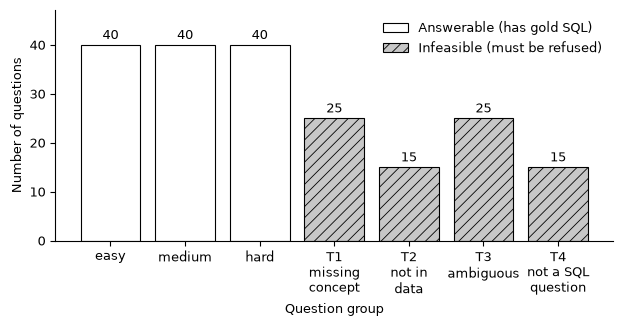

In [2]:
fig = draw("fig4_2_benchmark_composition")

## Figure 7.1 â€” Execution accuracy by difficulty

Execution accuracy (the share of answerable questions whose result equals the gold result)
for easy, medium and hard questions. Each panel is one model; the white bar is C0 (no
verification) and the hatched bar is C4 (full verification, at the model's dev-chosen Ï„).
An answerable question that C4 abstains on counts as not correct here.
Source: `e1_ex_by_model_difficulty.csv`.

saved results/figures/fig7_1_ex_by_model_difficulty.png


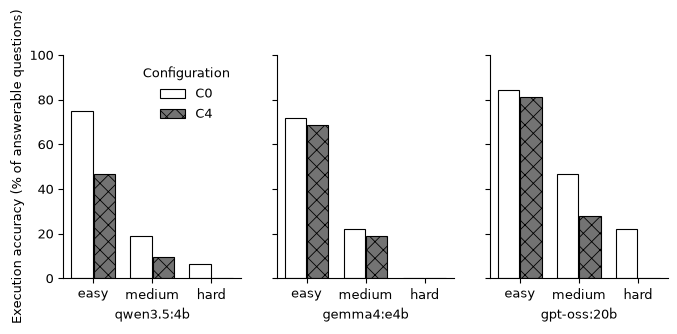

In [3]:
fig = draw("fig7_1_ex_by_model_difficulty")

## Figure 7.2 â€” Harmful answers by configuration

The number of harmful answers out of the 160 test questions for C0 to C4, per model. A
harmful answer is a wrong answer to an answerable question or any answer to an infeasible
question. Error bars are 95% bootstrap intervals (2,000 resamples of the test questions,
stratified by group, Ï„ fixed). Source: `e3_harmful_ci.csv`.

saved results/figures/fig7_2_harmful_by_config.png


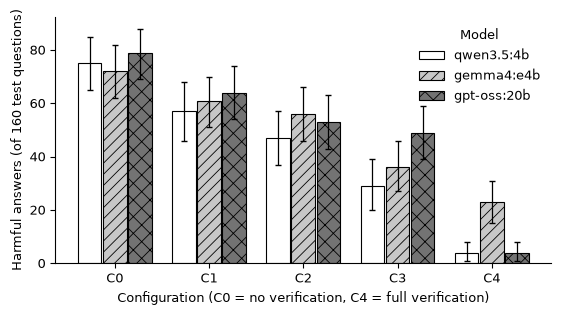

In [4]:
fig = draw("fig7_2_harmful_by_config")

## Figure 7.3 â€” Reliability Score against the penalty

The Reliability Score RS_c at penalty c = 0, 1 and 10. One panel per model, one line per
configuration. RS_c gives +1 for a correct answer or a justified abstention, 0 for
abstaining on an answerable question and âˆ’c for a harmful answer, times 100 and averaged
over the test questions. RS_c falls in a straight line as c grows (by c times the harmful
answers as a % of questions), so each line runs from RS_0 to RS_10 on a true numeric axis;
the markers are the reported values at c = 0, 1 and 10. Source: `e2_rs_by_config_penalty.csv`.

saved results/figures/fig7_3_rs_vs_penalty.png


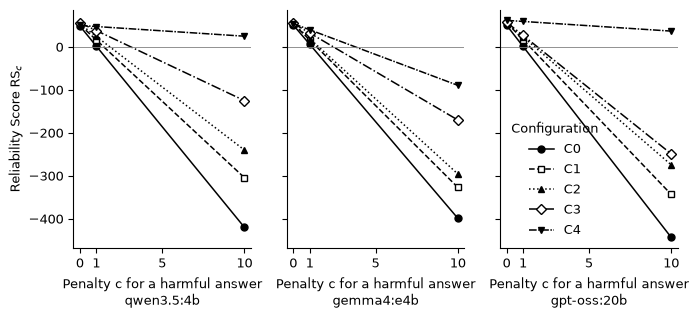

In [5]:
fig = draw("fig7_3_rs_vs_penalty")

## Figure 7.4 â€” Types of harmful answers

The harmful answers of each model at C0 and C4, split by type: an infeasible question was
answered; the SQL used an unknown table or column; the SQL does not run; the SQL runs but
returns the wrong result. The taxonomy's fifth type, "value", is 0 for every model and
configuration and is therefore not drawn. Source: `e3_taxonomy.csv`.

saved results/figures/fig7_4_taxonomy_stacked.png


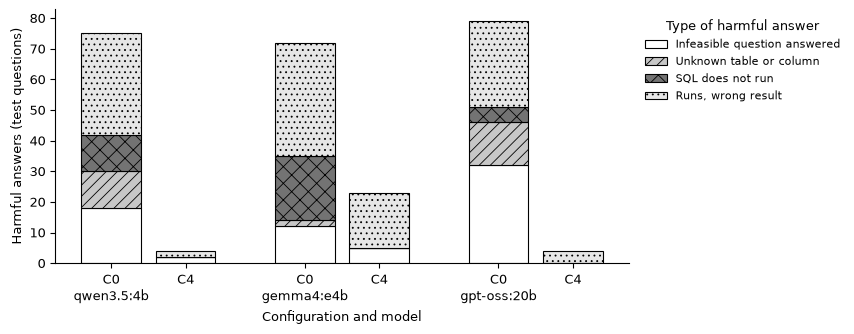

In [6]:
fig = draw("fig7_4_taxonomy_stacked")

## Figure 7.5 â€” ROC curves of the abstention signals

ROC curves of three signals for "this answer is wrong", over the questions each model
answered under the abstain prompt (C1): 1 âˆ’ agreement from the self-consistency check,
100 âˆ’ the model's stated confidence, and the length of the SQL as a baseline. The grey
diagonal is a signal with no information. The legend gives each curve's AUROC; intervals
are in `e4_auroc_ci.csv`. Sources: `e4_roc_points.csv`, `e4_signal_auroc.csv`.

saved results/figures/fig7_5_roc_signals.png


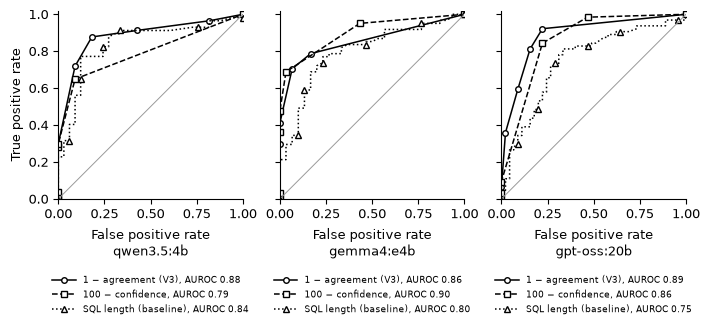

In [7]:
fig = draw("fig7_5_roc_signals")

## Figure 7.6 â€” Risk against coverage

What C4 does on the test split as the agreement threshold Ï„ takes the values 0, 0.2, â€¦, 1.
Coverage is the share of questions answered; risk is the share of those answers that are
harmful. Each line is one model, with one marker per Ï„ (some Ï„ values give the same point).
The large filled marker is the Ï„ chosen for that model on the dev split.
Sources: `e4_risk_coverage.csv`, `tau_selection.csv`.

saved results/figures/fig7_6_risk_coverage.png


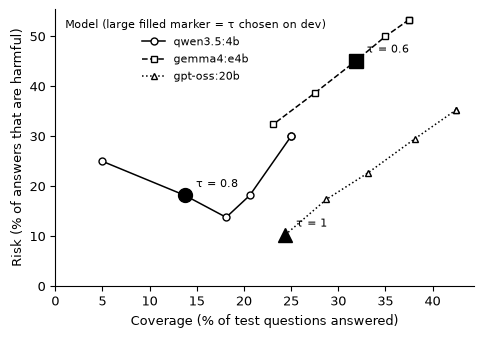

In [8]:
fig = draw("fig7_6_risk_coverage")

## Figure 7.7 â€” Infeasible questions answered

How many infeasible test questions each model answered, by trap group: T1 missing concept,
T2 not in data, T3 ambiguous, T4 not a SQL question. The white bar is C0, the hatched bar is
C4. The number of questions in each group is under its label.
Source: `e7_infeasible_by_group.csv`.

saved results/figures/fig7_7_infeasible_answered.png


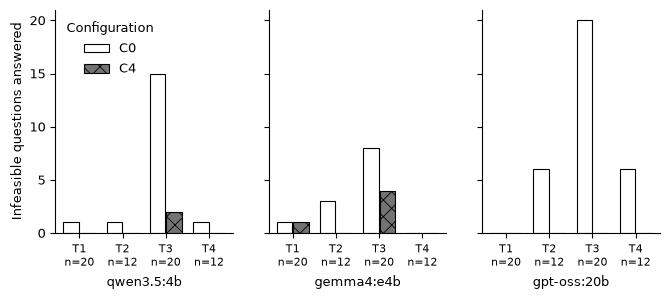

In [9]:
fig = draw("fig7_7_infeasible_answered")

## Report tables

The two report-ready tables written by the report command, shown here for convenience.

In [10]:
display(pd.read_csv(TABLES / "table6_1_models.csv"))
display(pd.read_csv(TABLES / "table7_1_latency_cost.csv"))
display(pd.read_csv(TABLES / "differences_ci.csv"))

,model_key,maker,ollama_tag,parameters,quantization,size_gb,settings,hardware,mean_seconds_per_call
0,qwen,Alibaba,qwen3.5:4b,4.2B,Q4_K_M,3.3,think=false; num_ctx=8192; max_tokens=600,Kaggle 2x Tesla T4; 1 GPU used (GPU 0: 3985 Mi...,2.81
1,gemma,Google,gemma4:e4b,7.5B,Q4_K_M,6.6,think=false; num_ctx=8192; max_tokens=600,Kaggle 2x Tesla T4; 1 GPU used (GPU 0: 4995 Mi...,1.46
2,mid_oss,OpenAI,gpt-oss:20b,20.9B,MXFP4,13.8,think=low; num_ctx=8192; max_tokens=1500,Kaggle 2x Tesla T4; split across both (GPU 0: ...,3.95


,model_key,ollama_tag,questions,calls_per_question,mean_seconds_per_call,p50_seconds_per_call,p95_seconds_per_call,seconds_per_question_c1_to_c3,seconds_per_question_c4,prompt_tokens_per_question,completion_tokens_per_question
0,qwen,qwen3.5:4b,200,7.13,2.81,1.88,8.85,3.06,16.49,21368,868
1,gemma,gemma4:e4b,200,7.03,1.46,1.11,3.47,1.40,8.77,21769,657
2,mid_oss,gpt-oss:20b,200,7.01,3.95,2.77,9.79,3.84,23.30,20360,1317


,comparison,metric,difference,lo,hi,resamples_used,interval_excludes_zero
0,qwen C4 minus qwen C0,rs_10,445.0000,379.3800,508.7500,2000,yes
1,qwen C4 minus qwen C0,harmful,-71.0000,-81.0000,-61.0000,2000,yes
2,gemma C4 minus gemma C0,rs_10,309.3800,245.0000,368.1400,2000,yes
3,gemma C4 minus gemma C0,harmful,-49.0000,-58.0000,-39.0000,2000,yes
4,mid_oss C4 minus mid_oss C0,rs_10,480.0000,418.1200,542.5000,2000,yes
5,mid_oss C4 minus mid_oss C0,harmful,-75.0000,-84.0000,-66.0000,2000,yes
6,qwen C4 minus mid_oss C0,rs_10,468.1200,399.3800,533.7500,2000,yes
7,gemma C4 minus mid_oss C0,rs_10,353.7500,275.6100,431.2500,2000,yes
8,mid_oss C4 minus qwen C4,rs_10,11.8800,-24.3800,49.3800,2000,no
9,mid_oss C4 minus gemma C4,rs_10,126.2500,71.8800,179.3800,2000,yes
